导包，设置基础绘图主体，字体信息

In [1]:
from pathlib import Path  # 导入路径处理工具 Path
import copy  # 导入深拷贝模块 copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt #底层绘图库
import seaborn as sns  # 导入统计绘图库 seaborn
from IPython.display import display
from sklearn.metrics import confusion_matrix, classification_report  # 导入混淆矩阵和分类报告评估函数
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader  # 导入数据集封装和数据加载器

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='white')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'DejaVu Sans']  # 设置中文字体避免乱码
plt.rcParams['axes.unicode_minus'] = False  # 设置坐标轴负号正常显示


路径，参数，随机数种子，设备定义

In [2]:
# 参数配置  # 说明当前单元用于集中配置实验参数
PROJECT_ROOT = Path.cwd()  # 获取当前项目根目录路径
print(PROJECT_ROOT)  # 打印当前项目根目录
DATA_PATH = PROJECT_ROOT / 'processed' / 'cwru_0hp_trainval_1hp_test_w1024_s512.npz'  # 设置预处理数据文件路径
MODEL_SAVE_PATH = PROJECT_ROOT / 'best_cross_condition_cnn_model.pth'  # 设置最优模型参数保存路径

BATCH_SIZE = 64  # 设置每个批次的样本数
DROPOUT = 0.3  # 设置分类器中的 dropout 比例
LEARNING_RATE = 1e-2  # 设置优化器学习率
WEIGHT_DECAY = 1e-4  # 设置权重衰减系数用于正则化
NUM_EPOCHS = 100  # 设置最大训练轮数
EARLY_STOPPING_PATIENCE = 10  # 设置早停容忍轮数
RANDOM_SEED = 42  # 设置全局随机数种子
random.seed(RANDOM_SEED)  # 固定 Python 随机数种子
np.random.seed(RANDOM_SEED)  # 固定 numpy 随机数种子
torch.manual_seed(RANDOM_SEED)  # 固定 PyTorch CPU 随机数种子
if torch.cuda.is_available():  # 如果当前环境支持 CUDA
    torch.cuda.manual_seed_all(RANDOM_SEED)  # 固定所有 GPU 的随机数种子

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # 自动选择训练设备为 GPU 或 CPU
print('数据文件:', DATA_PATH)  # 打印数据文件路径
print('训练设备:', device)  # 打印当前训练设备


/Users/leonshang/Desktop/cwru
数据文件: /Users/leonshang/Desktop/cwru/processed/cwru_0hp_trainval_1hp_test_w1024_s512.npz
训练设备: cpu


数据读取，设置训练集，测试集个数，确认滑动窗口

In [3]:
# 读取数据并标准化  # 说明当前单元用于加载和标准化数据
data = np.load(DATA_PATH, allow_pickle=True)  # 读取保存好的 npz 数据文件
X_train = data['X_train'].astype(np.float32)  # 读取训练集特征并转换为 float32
y_train = data['y_train'].astype(np.int64)  # 读取训练集标签并转换为 int64
X_val = data['X_val'].astype(np.float32)  # 读取验证集特征并转换为 float32
y_val = data['y_val'].astype(np.int64)  # 读取验证集标签并转换为 int64
X_test = data['X_test'].astype(np.float32)  # 读取测试集特征并转换为 float32
y_test = data['y_test'].astype(np.int64)  # 读取测试集标签并转换为 int64
label_names = [str(x) for x in data['label_names'].tolist()]  # 读取类别名称并统一转换为字符串列表

train_mean = X_train.mean()
train_std = X_train.std()
train_std = train_std if train_std > 1e-6 else 1.0  # 如果标准差过小则回退到 1.0 以避免除零

X_train = ((X_train - train_mean) / train_std).astype(np.float32)  # 使用训练集统计量标准化训练集
X_val = ((X_val - train_mean) / train_std).astype(np.float32)  # 使用训练集统计量标准化验证集
X_test = ((X_test - train_mean) / train_std).astype(np.float32)  # 使用训练集统计量标准化测试集

print('X_train:', X_train.shape)
print('X_val:', X_val.shape)  # 打印验证集特征形状
print('X_test:', X_test.shape)  # 打印测试集特征形状
print('类别名称:', label_names)  # 打印类别名称列表


X_train: (2084, 1024)
X_val: (521, 1024)
X_test: (3074, 1024)
类别名称: ['正常', '滚动体故障', '内圈故障', '外圈故障']


构建TensorDataset和DataLoader
TensorDataset：特征张量和标签张量捆绑一起，配对打包
DataLoader：打包后的数据按批次切分，打乱喂给数据

In [4]:

train_dataset = TensorDataset(torch.tensor(X_train).unsqueeze(1), torch.tensor(y_train))  # 将训练集特征和标签封装为 TensorDataset
val_dataset = TensorDataset(torch.tensor(X_val).unsqueeze(1), torch.tensor(y_val))  # 将验证集特征和标签封装为 TensorDataset
test_dataset = TensorDataset(torch.tensor(X_test).unsqueeze(1), torch.tensor(y_test))  # 将测试集特征和标签封装为 TensorDataset

train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)  # 构建训练集 DataLoader 并开启随机打乱
val_loader = DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)  # 构建验证集 DataLoader 且不打乱顺序
test_loader = DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)  # 构建测试集 DataLoader 且不打乱顺序

print('训练批次数:', len(train_loader))  # 打印训练集批次数
print('验证批次数:', len(val_loader))  # 打印验证集批次数
print('测试批次数:', len(test_loader))  # 打印测试集批次数

训练批次数: 33
验证批次数: 9
测试批次数: 49


定义CNN分类模型，3次卷积操作，获得最终64通道特征的提取

In [5]:
# 定义 CNN 分类模型  # 说明当前单元用于定义一维卷积分类网络
class CNNClassifier(nn.Module):  # 定义 CNN 分类器类并继承 nn.Module
    def __init__(self, num_classes, dropout):  # 定义初始化函数并接收类别数和 dropout 比例
        super().__init__()  # 调用父类初始化方法
        self.features = nn.Sequential(  # 定义卷积特征提取模块
            nn.Conv1d(1, 16, kernel_size=7, padding=3,stride=1),  # 第一层一维卷积将通道数从 1 提升到 16
            nn.ReLU(),  # 添加 ReLU 激活函数
            nn.MaxPool1d(kernel_size=2),  # 使用最大池化将时序长度减半
            nn.Conv1d(16, 32, kernel_size=5, padding=2,stride=1),  # 第二层一维卷积将通道数从 16 提升到 32
            nn.ReLU(),  # 添加 ReLU 激活函数
            nn.MaxPool1d(kernel_size=2),  # 再次使用最大池化将时序长度减半
            nn.Conv1d(32, 64, kernel_size=3, padding=1,stride=1),  # 第三层一维卷积将通道数从 32 提升到 64
            nn.ReLU(),  # 添加 ReLU 激活函数
            nn.AdaptiveAvgPool1d(1)  # 使用自适应平均池化将每个通道压缩到长度 1
        )  # 完成卷积特征提取模块定义
        self.classifier = nn.Sequential(  # 定义分类头模块
            nn.Flatten(),  # 将卷积输出展平成二维张量
            nn.Dropout(dropout),  # 添加 dropout 以减轻过拟合
            nn.Linear(64, num_classes)  # 使用线性层输出每个类别的 logits
        )  # 完成分类头模块定义

    def forward(self, x):  # 定义前向传播函数
        x = self.features(x)  # 先通过卷积特征提取模块
        x = self.classifier(x)  # 再通过分类头得到分类输出
        return x  # 返回最终预测结果


model = CNNClassifier(num_classes=len(label_names), dropout=DROPOUT).to(device)  # 实例化 CNN 模型并移动到目标设备
criterion = nn.CrossEntropyLoss()  # 定义交叉熵损失函数
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)  # 定义 Adam 优化器
model  # 在 Notebook 中显示模型结构


CNNClassifier(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): ReLU()
    (8): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=4, bias=True)
  )
)

定义损失函数，优化器，学习率

In [6]:

def train_one_epoch(model, loader, criterion, optimizer):  # 定义单轮训练函数
    model.train()  # 将模型切换到训练模式
    total_loss, total_correct, total_samples = 0.0, 0, 0  # 初始化总损失、总正确数和总样本数

    for batch_x, batch_y in loader:  # 遍历训练集中的每一个批次
        batch_x = batch_x.to(device)  # 将当前批次特征移动到目标设备
        batch_y = batch_y.to(device)  # 将当前批次标签移动到目标设备

        optimizer.zero_grad()  # 清空上一轮反向传播累积的梯度
        logits = model(batch_x)  # 将当前批次输入模型得到预测 logits
        loss = criterion(logits, batch_y)  # 计算当前批次的损失值
        loss.backward()  # 反向传播计算梯度
        optimizer.step()  # 使用优化器更新模型参数

        total_loss += loss.item() * batch_x.size(0)  # 累加当前批次的总损失
        total_correct += (logits.argmax(dim=1) == batch_y).sum().item()  # 累加当前批次预测正确的样本数
        total_samples += batch_x.size(0)  # 累加当前批次的样本数

    return total_loss / total_samples, total_correct / total_samples  # 返回本轮平均损失和平均准确率


def evaluate(model, loader, criterion):  # 定义评估函数用于验证集或测试集
    model.eval()  # 将模型切换到评估模式
    total_loss, total_correct, total_samples = 0.0, 0, 0  # 初始化总损失、总正确数和总样本数

    with torch.no_grad():  # 在不计算梯度的上下文中执行评估
        for batch_x, batch_y in loader:  # 遍历验证集或测试集中的每一个批次
            batch_x = batch_x.to(device)  # 将当前批次特征移动到目标设备
            batch_y = batch_y.to(device)  # 将当前批次标签移动到目标设备

            logits = model(batch_x)  # 将当前批次输入模型得到预测 logits
            loss = criterion(logits, batch_y)  # 计算当前批次的损失值

            total_loss += loss.item() * batch_x.size(0)  # 累加当前批次的总损失
            total_correct += (logits.argmax(dim=1) == batch_y).sum().item()  # 累加当前批次预测正确的样本数
            total_samples += batch_x.size(0)  # 累加当前批次的样本数

    return total_loss / total_samples, total_correct / total_samples  # 返回平均损失和平均准确率


def predict(model, loader):  # 定义预测函数用于收集真实标签和预测标签
    model.eval()  # 将模型切换到评估模式
    y_true, y_pred = [], []  # 初始化真实标签列表和预测标签列表

    with torch.no_grad():  # 在不计算梯度的上下文中执行预测
        for batch_x, batch_y in loader:  # 遍历数据加载器中的每一个批次
            batch_x = batch_x.to(device)  # 将当前批次特征移动到目标设备
            logits = model(batch_x)  # 将当前批次输入模型得到预测 logits
            preds = logits.argmax(dim=1).cpu().numpy()  # 取最大概率类别并转为 numpy 数组
            y_pred.append(preds)  # 将当前批次预测结果加入预测列表
            y_true.append(batch_y.numpy())  # 将当前批次真实标签加入真实列表

    return np.concatenate(y_true), np.concatenate(y_pred)  # 拼接所有批次结果并返回


def plot_history(history, model_name):  # 定义训练历史曲线绘制函数
    epochs = np.arange(1, len(history['train_loss']) + 1)  # 生成从 1 开始的 epoch 序列
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=160)  # 创建包含两个子图的画布

    for ax in axes:  # 遍历每个子图对象
        ax.spines['top'].set_visible(False)  # 隐藏上边框
        ax.spines['right'].set_visible(False)  # 隐藏右边框
        ax.grid(alpha=0.2, linestyle='--')  # 设置浅色虚线网格

    axes[0].plot(epochs, history['train_loss'], color='#1f77b4', linewidth=2.2, label='训练损失')  # 绘制训练损失曲线
    axes[0].plot(epochs, history['val_loss'], color='#d62728', linewidth=2.2, label='验证损失')  # 绘制验证损失曲线
    axes[0].set_title(f'{model_name} 损失曲线', fontweight='bold')  # 设置损失曲线子图标题
    axes[0].set_xlabel('Epoch')  # 设置损失曲线横坐标标签
    axes[0].set_ylabel('Loss')  # 设置损失曲线纵坐标标签
    axes[0].legend(frameon=False)  # 显示损失曲线图例并去掉边框

    axes[1].plot(epochs, history['train_acc'], color='#2ca02c', linewidth=2.2, label='训练准确率')  # 绘制训练准确率曲线
    axes[1].plot(epochs, history['val_acc'], color='#9467bd', linewidth=2.2, label='验证准确率')  # 绘制验证准确率曲线
    axes[1].set_title(f'{model_name} 准确率曲线', fontweight='bold')  # 设置准确率曲线子图标题
    axes[1].set_xlabel('Epoch')  # 设置准确率曲线横坐标标签
    axes[1].set_ylabel('Accuracy')  # 设置准确率曲线纵坐标标签
    axes[1].set_ylim(0, 1.02)  # 设置准确率纵坐标显示范围
    axes[1].legend(frameon=False)  # 显示准确率曲线图例并去掉边框

    plt.tight_layout()  # 自动调整子图间距避免重叠
    plt.show()  # 显示训练历史曲线图


开始训练，训练验证测试，打印最佳训练结果论次

In [7]:

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}  # 初始化用于记录训练历史的字典
best_val_loss = float('inf')  # 将最佳验证损失初始化为正无穷
best_state = None  # 初始化用于保存最优模型参数的变量
best_epoch = 0  # 初始化最佳轮次编号
wait = 0  # 初始化早停等待计数器

for epoch in range(1, NUM_EPOCHS + 1):  # 按照设定轮数循环训练模型
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)  # 执行一轮训练并获得训练损失和准确率
    val_loss, val_acc = evaluate(model, val_loader, criterion)  # 在验证集上评估当前模型

    history['train_loss'].append(train_loss)  # 记录当前轮的训练损失
    history['val_loss'].append(val_loss)  # 记录当前轮的验证损失
    history['train_acc'].append(train_acc)  # 记录当前轮的训练准确率
    history['val_acc'].append(val_acc)  # 记录当前轮的验证准确率

    if val_loss < best_val_loss:  # 如果当前验证损失优于历史最佳
        best_val_loss = val_loss  # 更新最佳验证损失
        best_state = copy.deepcopy(model.state_dict())  # 深拷贝保存当前最优模型参数
        best_epoch = epoch  # 记录当前最佳轮次
        wait = 0  # 重置早停等待计数器
    else:  # 如果当前验证损失没有提升
        wait += 1  # 将早停等待计数器加一

    print(f'Epoch [{epoch:02d}/{NUM_EPOCHS}] train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f}')  # 打印当前轮训练与验证结果

    if wait >= EARLY_STOPPING_PATIENCE:  # 如果连续未提升轮数达到早停阈值
        print(f'触发早停，训练在第 {epoch} 轮结束。')  # 打印早停提示信息
        break  # 提前结束训练循环

model.load_state_dict(best_state)  # 将模型参数恢复到验证集表现最好的状态
torch.save(best_state, MODEL_SAVE_PATH)  # 将最优模型参数保存到磁盘
print('最优模型已保存到:', MODEL_SAVE_PATH)  # 打印最优模型保存路径
print('最佳轮次:', best_epoch)  # 打印最佳轮次编号


Epoch [01/100] train_loss=0.8755 train_acc=0.6008 val_loss=0.4427 val_acc=0.8464
Epoch [02/100] train_loss=0.4158 train_acc=0.8215 val_loss=0.2413 val_acc=0.8944
Epoch [03/100] train_loss=0.2185 train_acc=0.8892 val_loss=0.0969 val_acc=0.9962
Epoch [04/100] train_loss=0.1359 train_acc=0.9506 val_loss=0.0603 val_acc=0.9808
Epoch [05/100] train_loss=0.0478 train_acc=0.9885 val_loss=0.0100 val_acc=1.0000
Epoch [06/100] train_loss=0.0365 train_acc=0.9885 val_loss=0.0045 val_acc=1.0000
Epoch [07/100] train_loss=0.0264 train_acc=0.9928 val_loss=0.0258 val_acc=0.9923
Epoch [08/100] train_loss=0.0450 train_acc=0.9842 val_loss=0.0436 val_acc=0.9923
Epoch [09/100] train_loss=0.0390 train_acc=0.9918 val_loss=0.0136 val_acc=0.9962
Epoch [10/100] train_loss=0.4140 train_acc=0.9098 val_loss=0.4315 val_acc=0.7678
Epoch [11/100] train_loss=0.1627 train_acc=0.9515 val_loss=0.0399 val_acc=0.9942
Epoch [12/100] train_loss=0.0585 train_acc=0.9818 val_loss=0.0153 val_acc=1.0000
Epoch [13/100] train_loss=0.

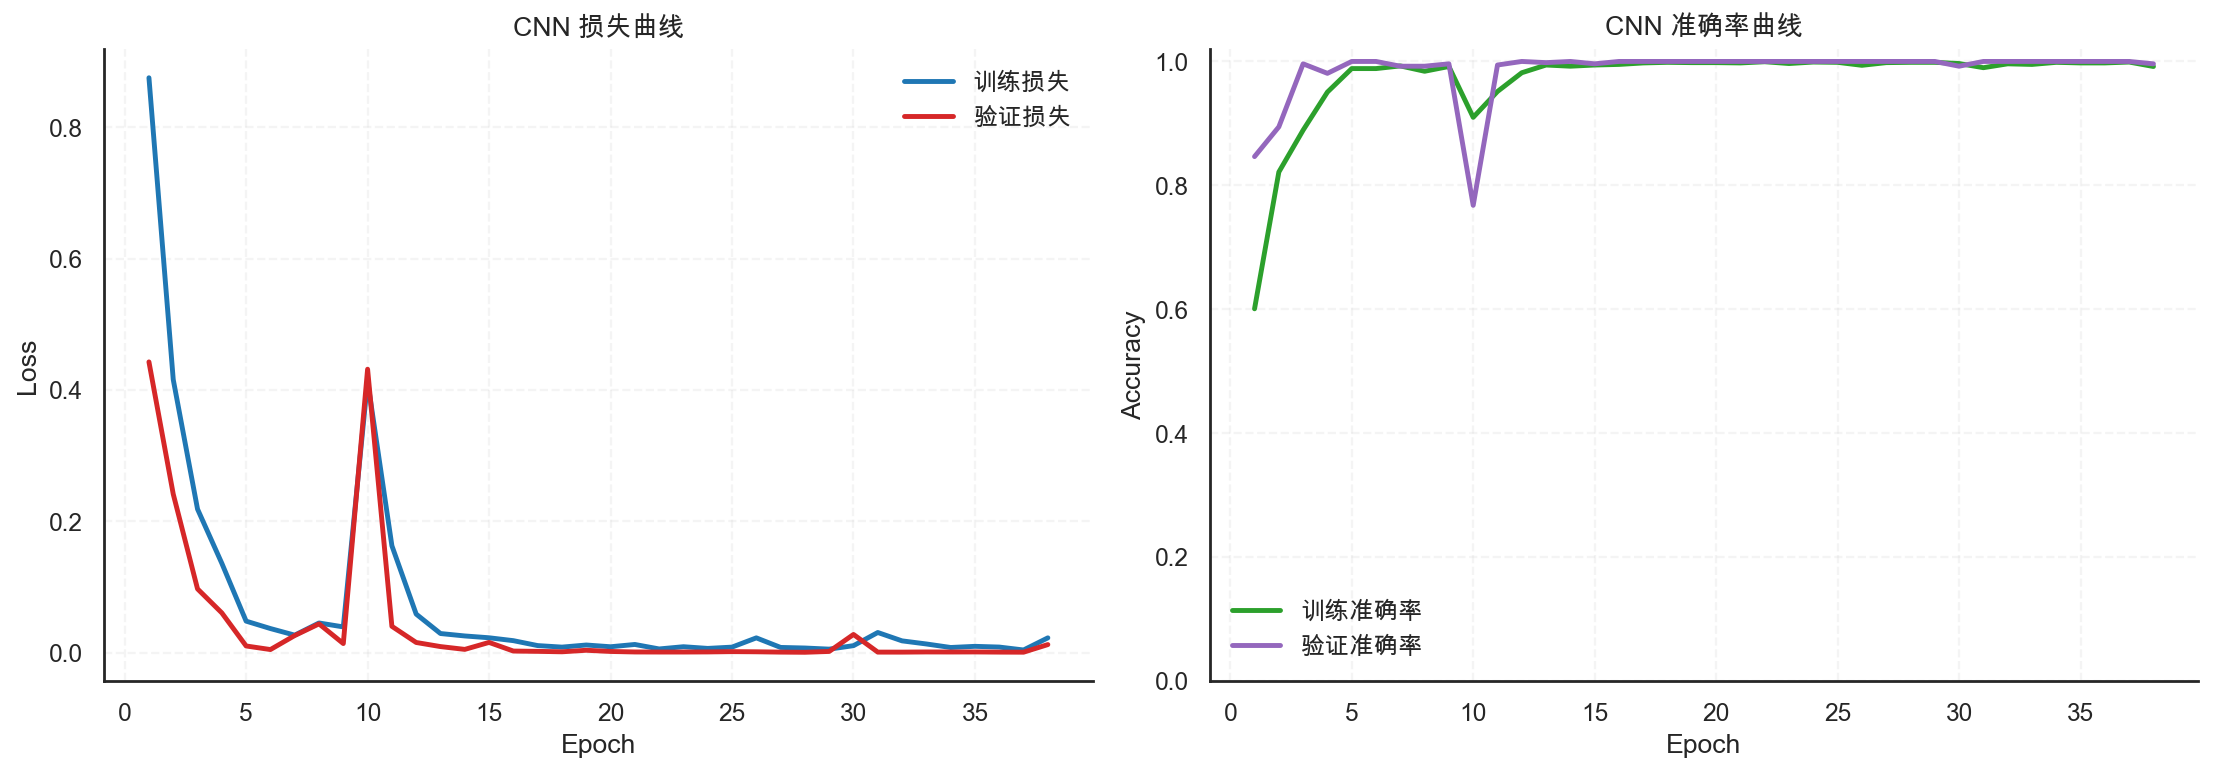

In [8]:
# 绘制训练曲线  # 说明当前单元用于可视化训练过程
plot_history(history, 'CNN')  # 调用绘图函数绘制 CNN 的训练历史曲线


In [9]:
# 测试集评估  # 说明当前单元用于在测试集上评估模型
test_loss, test_acc = evaluate(model, test_loader, criterion)  # 计算测试集损失和准确率
y_true, y_pred = predict(model, test_loader)  # 获取测试集真实标签和预测标签

print(f'测试集损失: {test_loss:.4f}')  # 打印测试集损失
print(f'测试集准确率: {test_acc:.4f}')  # 打印测试集准确率


测试集损失: 0.1191
测试集准确率: 0.9408


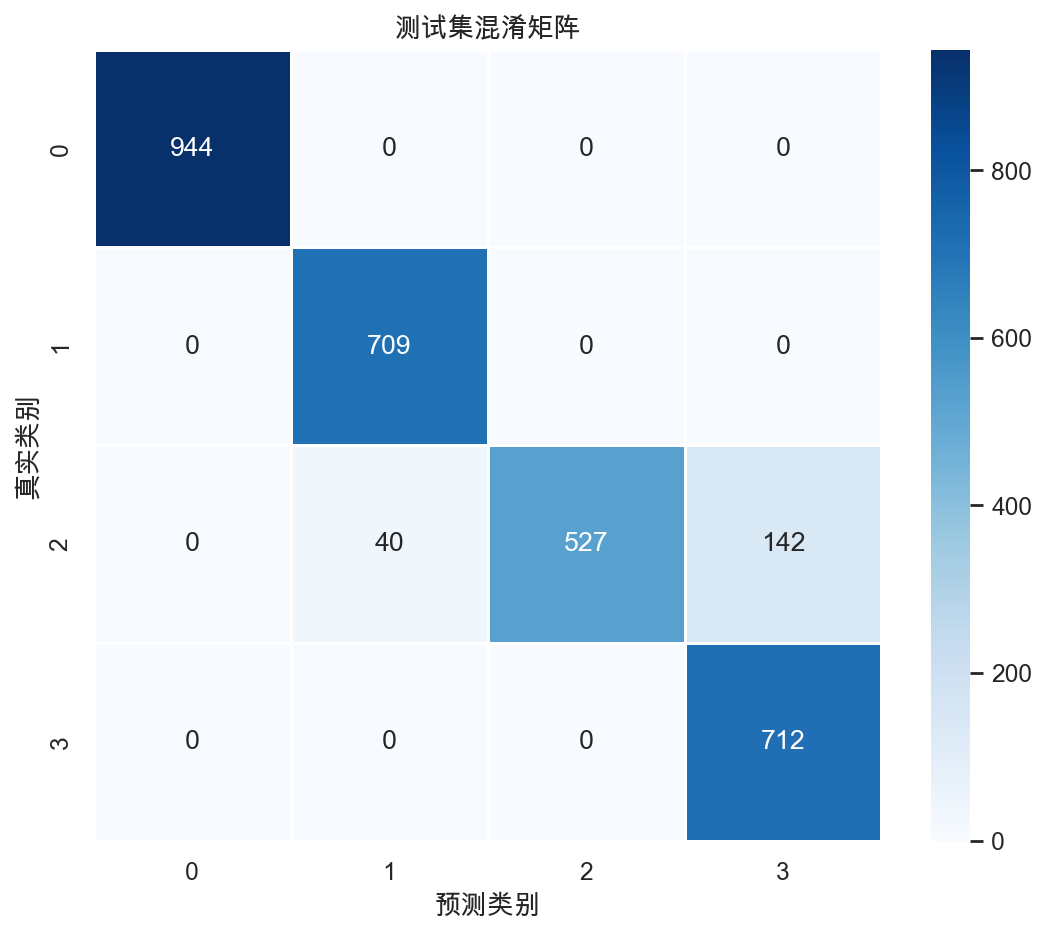

,precision,recall,f1-score,support
正常,1.000000,1.000000,1.000000,944.000000
滚动体故障,0.946595,1.000000,0.972565,709.000000
内圈故障,1.000000,0.743300,0.852751,709.000000
外圈故障,0.833724,1.000000,0.909323,712.000000
accuracy,0.940794,0.940794,0.940794,0.940794
macro avg,0.945080,0.935825,0.933660,3074.000000
weighted avg,0.949170,0.940794,0.938708,3074.000000


In [10]:
# 混淆矩阵和分类报告  # 说明当前单元用于展示分类评估结果
cm = confusion_matrix(y_true, y_pred)  # 根据真实标签和预测标签计算混淆矩阵
plt.figure(figsize=(7, 6), dpi=160)  # 创建混淆矩阵图像画布
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=0.5, linecolor='white')  # 绘制带数字标注的混淆矩阵热力图
plt.title('测试集混淆矩阵', fontweight='bold')  # 设置混淆矩阵标题
plt.xlabel('预测类别')  # 设置横坐标标签为预测类别
plt.ylabel('真实类别')  # 设置纵坐标标签为真实类别
plt.tight_layout()  # 自动调整图像布局避免重叠
plt.show()  # 显示混淆矩阵图

report_df = pd.DataFrame(classification_report(y_true, y_pred, target_names=label_names, output_dict=True, zero_division=0)).T  # 生成分类报告并转为 DataFrame
display(report_df)  # 展示分类报告表格
